# Adding Problem: Long-Term Dependency Learning Task

This notebook implements the adding problem, a benchmark task for evaluating the ability of RNNs to learn long-term dependencies. The task requires computing the sum of two specific numbers from a sequence of random numbers.

## Task Description

- Input: 2-dimensional vector at each time step
  - First dimension: Random number in [0, 1]
  - Second dimension: Boolean indicator (1 for numbers to add, 0 otherwise)
- Sequence length: 20 time steps
- Objective: Sum the two numbers where the boolean indicator is 1
- This tests the network's ability to remember and combine information from different time steps

We will compare the performance of two network architectures:

1. **Net**: RNN with excitatory/inhibitory separation
2. **SimpleNet**: Standard vanilla RNN


## 1. Setup and Imports


In [21]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import warnings
warnings.filterwarnings('ignore')

from pdm_model import Net, SimpleNet

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


## 2. Adding Problem Dataset


In [ ]:
class ParenthesisDataset(Dataset):
    def __init__(self, seq_len=64, num_samples=100000):
        self.seq_len = seq_len
        self.num_samples = num_samples

        self.data = torch.zeros(num_samples, seq_len, 1, dtype=torch.float32)
        # self.data = torch.randint(0, 2, (num_samples, seq_len, 1), dtype=torch.float32)
        self.target = torch.zeros(num_samples, dtype=torch.long)
        for i in range(num_samples):
            # 随机生成括号序列 (0= "(", 1= ")")
            if np.random.rand() < 0.5:
                seq = self.generate_valid()
                self.target[i] = 1  # 合法
            else:
                seq = self.generate_invalid()
                self.target[i] = 0
            self.data[i, :, 0] = torch.FloatTensor(seq)

        self.input_size = 1
        self.output_size = 2  # 合法 or 不合法

    def generate_valid(self):
        seq = np.zeros(self.seq_len, dtype=int)
        balance = 0
        for i in range(self.seq_len):
            if balance == 0:
                seq[i] = 0  # "("
                balance += 1
            elif balance == self.seq_len - i:
                seq[i] = 1  # ")"
                balance -= 1
            else:
                if np.random.rand() < 0.5:
                    seq[i] = 0  # "("
                    balance += 1
                else:
                    seq[i] = 1  # ")"
                    balance -= 1
        return seq
    def generate_invalid(self):
        return np.random.randint(0, 2, size=self.seq_len)
    def is_valid(self, seq):
        """检查括号序列是否合法"""
        balance = 0
        for s in seq:
            if s == 0:  # "("
                balance += 1
            else:  # ")"
                balance -= 1
            if balance < 0:  # 出现多余的 ")"
                return 0
        return 1 if balance == 0 else 0  # 必须全部匹配才合法

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        return self.data[idx], self.target[idx]


# Create datasets
train_dataset = ParenthesisDataset(seq_len=20, num_samples=50000)
test_dataset = ParenthesisDataset(seq_len=20, num_samples=1000)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

# Show example
for i in range(10):
    idx = np.random.randint(0, len(train_dataset))
    sample_input, sample_target = train_dataset[idx]
    print(f"\nExample input shape: {sample_input.squeeze()}")
    print(f"Example target: {sample_target}")

Training dataset size: 50000
Test dataset size: 1000

Example input shape: tensor([1., 0., 1., 0., 1., 0., 1., 1., 1., 1., 0., 1., 0., 0., 0., 1., 0., 0.,
        1., 0., 0., 0., 0., 0., 1., 0., 0., 0., 1., 1., 0., 0., 1., 0., 1., 1.,
        1., 1., 1., 1., 0., 0., 0., 1., 1., 1., 1., 0., 1., 1.])
Example target: 0

Example input shape: tensor([0., 1., 0., 1., 0., 1., 0., 0., 0., 0., 1., 1., 1., 0., 1., 1., 0., 0.,
        0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 1., 1.,
        0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])
Example target: 1

Example input shape: tensor([0., 1., 1., 1., 1., 0., 0., 1., 1., 1., 1., 0., 0., 1., 1., 0., 1., 0.,
        1., 0., 0., 1., 0., 0., 0., 0., 1., 1., 0., 0., 0., 1., 0., 0., 0., 0.,
        0., 0., 0., 0., 1., 0., 1., 1., 0., 1., 0., 0., 0., 1.])
Example target: 0

Example input shape: tensor([1., 0., 1., 1., 0., 0., 1., 1., 1., 0., 1., 1., 1., 1., 0., 0., 0., 1.,
        1., 0., 0., 0., 1., 0., 1., 0., 0., 1., 0.

## 3. Visualize Sample Data


In [23]:
def loss_fn(outputs, targets, criterion):
    """
    Compute cross-entropy loss between model outputs and targets.
    """
    T, B, D = outputs.shape
    predictions = outputs.reshape(T, B, T, T)
    assert targets.shape == (B, T, T)
    loss = 0
    acc = 0
    for t in range(T):
        prediction_t = predictions[t, :, :t+1].reshape(B*(t+1), T)
        target_t = targets[:, t, :t+1].reshape(B*(t+1))
        assert torch.all(target_t != -1)
        loss += criterion(prediction_t, target_t)
    loss /= T
    acc = predictions[-1].argmax(dim=-1).eq(targets[:,-1]).float().mean().item()
    return loss, acc

## 4. Training Functions


In [24]:
def train_model(model, train_dataset, test_dataset, epochs=100, lr=0.001, batch_size=64):
    """
    Train a model on the adding problem.
    """
    if isinstance(model, Net):
        special_params, other_params = [], []
        for name, p in model.named_parameters():
            if name == "lstm.eimask_logit":   # 或者用 name.endswith("eimask_logit")
                special_params.append(p)
                # assert p.requires_grad, "eimask_logit should be trainable"
            else:
                other_params.append(p)
        optimizer = torch.optim.Adam([{'params': special_params, 'lr': lr*10},
                                      {'params': other_params, 'lr': lr}])
    else:
        # For SimpleNet, use a single learning rate
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    # criterion = nn.L1Loss()

    train_losses = torch.zeros(epochs)
    test_every = 100
    test_losses = torch.zeros(epochs // test_every)
    test_accs = torch.zeros(epochs // test_every)

    model.train()
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    loader = iter(train_loader)
    for epoch in range(epochs):
        # print(epoch)
        # Training
        total_train_loss = 0
        num_batches = 0

        # for batch_inputs, batch_targets in train_loader:
        try:
            batch_inputs, batch_targets = next(loader)
        except StopIteration:
            train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
            loader = iter(train_loader)
            batch_inputs, batch_targets = next(loader)
        batch_inputs = batch_inputs.to(device).transpose(0, 1)  # (seq_len, batch_size, input_size)
        # print('batch_inputs:', batch_inputs.shape)
        batch_targets = batch_targets.to(device)  # (batch_size, )
        B = batch_targets.shape[0]

        # print('batch_targets:', batch_targets.shape)

        optimizer.zero_grad()

        # Forward pass
        outputs, eimask_logit, hidden = model(batch_inputs)

        predictions = outputs[-1]
        target = batch_targets
        decoding_loss = criterion(predictions, target)
        # decoding_loss, acc = loss_fn(outputs, batch_targets, criterion)

        if model.entropy_loss:
            # eimask_prob = F.softmax(eimask_logit, dim=-1)
            # eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)
            # entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization
            entropy_loss = model.get_ei_entropy_loss()
        else:
            entropy_loss = 0.0

        if isinstance(model, SimpleNet):
            l1_loss = model.lstm.Wrec_free.abs().mean()
        else:
            l1_loss = 0

        loss = 1 * entropy_loss + decoding_loss + l1_loss * 0
        # Backward pass
        loss.backward()
        # Gradient clipping for stability
        # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        total_train_loss += loss.item()
        num_batches += 1

        avg_train_loss = total_train_loss / num_batches
        train_losses[epoch] = avg_train_loss

        # Testing
        if epoch % test_every == 0:
            model.eval()
            total_test_loss = 0
            total_test_accuracy = 0
            num_test_batches = 0

            with torch.no_grad():
                for batch_inputs, batch_targets in test_loader:
                    batch_inputs = batch_inputs.to(device).transpose(0, 1)
                    batch_targets = batch_targets.to(device)  # (batch_size, )
                    B = batch_targets.shape[0]

                    outputs, _, hidden = model(batch_inputs)
                    # print('outputs:', outputs.shape)
                    predictions = outputs[-1]
                    target = batch_targets

                    loss = criterion(predictions, target)
                    # loss, accuracy = loss_fn(outputs, batch_targets, criterion)
                    predict_label = torch.argmax(predictions, dim=-1)
                    accuracy = (predict_label == target).float().mean().item()
                    total_test_loss += loss.item()
                    total_test_accuracy += accuracy
                    num_test_batches += 1

            avg_test_loss = total_test_loss / num_test_batches
            avg_test_accuracy = total_test_accuracy / num_test_batches
            test_losses[epoch // test_every] = avg_test_loss
            test_accs[epoch // test_every] = avg_test_accuracy

            print(f'Epoch [{epoch:4d}/{epochs}], Train Loss: {avg_train_loss:.6f}, Test Loss: {avg_test_loss:.6f}, Test Acc: {avg_test_accuracy:.4f}')

            model.train()

    return train_losses, test_losses

def evaluate_model(model, test_loader):
    """
    Evaluate model performance on test set.
    """
    model.eval()
    total_loss = 0
    total_accuracy = 0
    predictions = []
    targets = []

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for batch_inputs, batch_targets in test_loader:
            batch_inputs = batch_inputs.to(device).transpose(0, 1)
            batch_targets = batch_targets.to(device)
            B = batch_targets.shape[0]

            outputs, _, hidden = model(batch_inputs)
            preds = outputs[-1]
            target = batch_targets

            loss = criterion(preds, target)
            # loss, acc = loss_fn(outputs, batch_targets, criterion)
            total_loss += loss.item()
            # total_accuracy += acc

            predictions.extend(preds.cpu().numpy())
            targets.extend(batch_targets.cpu().numpy())

    avg_loss = total_loss / len(test_loader)
    accuracy = total_accuracy / len(test_loader)
    # print('type:', type(predictions), type(targets))
    # print(predictions, np.stack(predictions).shape)
    # print(targets, np.concatenate(targets).shape)
    # print('predictions shape:', np.stack(predictions).shape, 'targets shape:', np.concatenate(targets).shape)
    accuracy = np.mean((np.argmax(predictions, axis=-1) == targets).astype(np.float32))

    return avg_loss, accuracy, predictions, targets

## 5. Experiment: Compare Net vs SimpleNet


In [25]:
# Experiment parameters
n_seeds = 5
epochs = 2000
batch_size = 64
hidden_size = 64
input_size = train_dataset.input_size  # [number, indicator]
output_size = train_dataset.output_size  # regression output

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Storage for results
results = {
    'net': {'train_losses': [], 'test_losses': [], 'final_acc': []},
    'simple': {'train_losses': [], 'test_losses': [], 'final_acc': []}
}

print(f"Running experiment with {n_seeds} seeds...\n")
lr_ei = 1e-2
lr_simple = 1e-3
for seed in range(n_seeds):
    print(f"=== Seed {seed + 1}/{n_seeds} ===")

    # Set random seeds for reproducibility
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Train Net (EI-separated RNN)
    print("Training Net (EI-separated RNN)...")
    net = Net(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)
    train_losses_net, test_losses_net = train_model(net, train_dataset, test_dataset,
                                                  epochs=epochs, lr=lr_ei, batch_size=batch_size,)

    # Evaluate Net
    _, acc_net, net_predictions, net_targets = evaluate_model(net, test_loader)

    results['net']['train_losses'].append(train_losses_net)
    results['net']['test_losses'].append(test_losses_net)
    results['net']['final_acc'].append(acc_net)
    print(f"Net - Final Acc: {acc_net:.6f}")


    # Train SimpleNet (vanilla RNN)
    print("Training SimpleNet (vanilla RNN)...")
    simple_net = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)
    train_losses_simple, test_losses_simple = train_model(simple_net, train_dataset, test_dataset,
                                                          epochs=epochs,lr=lr_simple,batch_size=batch_size,)

    # Evaluate SimpleNet
    _, acc_simple, simple_predictions, simple_targets = evaluate_model(simple_net, test_loader)

    results['simple']['train_losses'].append(train_losses_simple.detach().cpu().numpy())
    results['simple']['test_losses'].append(test_losses_simple.detach().cpu().numpy())
    results['simple']['final_acc'].append(acc_simple)
    print(f"SimpleNet - Final Acc: {acc_simple:.6f}")




    print()

print("Experiment completed!")

Running experiment with 5 seeds...

=== Seed 1/5 ===
Training Net (EI-separated RNN)...
Epoch [   0/2000], Train Loss: 1.406419, Test Loss: 0.724266, Test Acc: 0.4123
Epoch [ 100/2000], Train Loss: 0.629397, Test Loss: 0.512205, Test Acc: 0.8248
Epoch [ 200/2000], Train Loss: 0.449677, Test Loss: 0.386991, Test Acc: 0.8248
Epoch [ 300/2000], Train Loss: 0.368493, Test Loss: 0.377000, Test Acc: 0.8395
Epoch [ 400/2000], Train Loss: 0.284469, Test Loss: 0.326275, Test Acc: 0.8350
Epoch [ 500/2000], Train Loss: 0.455464, Test Loss: 0.317919, Test Acc: 0.8340
Epoch [ 600/2000], Train Loss: 0.341981, Test Loss: 0.353574, Test Acc: 0.8430
Epoch [ 700/2000], Train Loss: 0.463106, Test Loss: 0.315621, Test Acc: 0.8314
Epoch [ 800/2000], Train Loss: 0.268862, Test Loss: 0.347676, Test Acc: 0.8240
Epoch [ 900/2000], Train Loss: 0.315619, Test Loss: 0.311028, Test Acc: 0.8354
Epoch [1000/2000], Train Loss: 0.374287, Test Loss: 0.303161, Test Acc: 0.8309
Epoch [1100/2000], Train Loss: 0.307580, Te

KeyboardInterrupt: 

## 6. Results Analysis


In [ ]:
# Print summary statistics
print("=== Final Results Summary ===")
print(f"Number of seeds: {n_seeds}")
print(f"Training epochs: {epochs}")
print(f"Hidden size: {hidden_size}")
print(f"Sequence length: 20")
print()

# Net results
net_acc_mean = np.mean(results['net']['final_acc'])
net_acc_std = np.std(results['net']['final_acc'])

print(f"Net (EI-separated RNN):")
print(f"  Acc: {net_acc_mean:.6f} ± {net_acc_std:.6f}")

# SimpleNet results
simple_acc_mean = np.mean(results['simple']['final_acc'])
simple_acc_std = np.std(results['simple']['final_acc'])

print(f"\nSimpleNet (vanilla RNN):")
print(f"  MSE: {simple_acc_mean:.6f} ± {simple_acc_std:.6f}")

# Improvement calculation
acc_improvement = (net_acc_mean - simple_acc_mean) / simple_acc_mean * 100

print(f"\n=== Performance Comparison ===")
print(f"Acc improvement (Net vs SimpleNet): {acc_improvement:.2f}%")

if acc_improvement > 0:
    print("Net (EI-separated) performs better than SimpleNet (vanilla RNN)")
else:
    print("SimpleNet (vanilla RNN) performs better than Net (EI-separated)")

=== Final Results Summary ===
Number of seeds: 5
Training epochs: 2000
Hidden size: 64
Sequence length: 20

Net (EI-separated RNN):
  Acc: 0.989600 ± 0.002059

SimpleNet (vanilla RNN):
  MSE: 0.981600 ± 0.012241

=== Performance Comparison ===
Acc improvement (Net vs SimpleNet): 0.81%
Net (EI-separated) performs better than SimpleNet (vanilla RNN)


## 7. Visualization


net train mean: [1.60893    1.4399002  1.396975   ... 0.04117978 0.08474766 0.06369697]
(array([], dtype=int64), array([], dtype=int64))


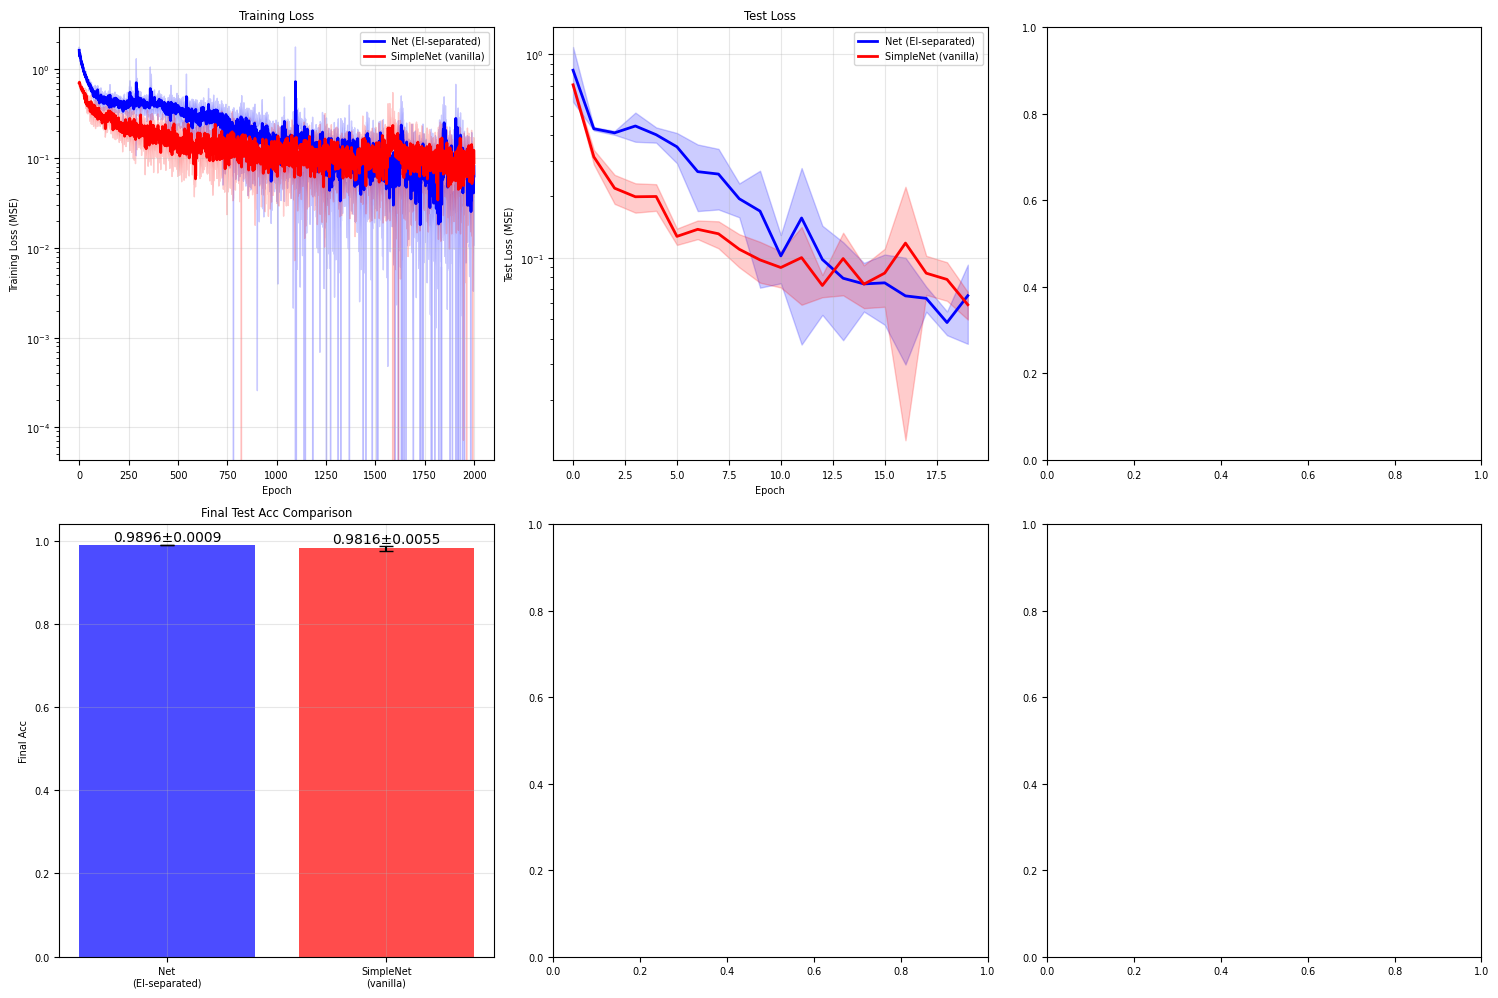

In [ ]:
def plot_learning_curves(results, n_seeds):
    """
    Plot learning curves for both models.
    """
    fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(15, 10))

    # Training loss curves
    net_train_losses = np.array(results['net']['train_losses'])
    simple_train_losses = np.array(results['simple']['train_losses'])

    net_train_mean = np.mean(net_train_losses, axis=0)
    net_train_std = np.std(net_train_losses, axis=0)
    simple_train_mean = np.mean(simple_train_losses, axis=0)
    simple_train_std = np.std(simple_train_losses, axis=0)
    print('net train mean:', net_train_mean)
    print(np.where(net_train_losses>100))

    epochs_range = range(len(net_train_mean))

    ax1.plot(epochs_range, net_train_mean, 'b-', label='Net (EI-separated)', linewidth=2)
    ax1.fill_between(epochs_range, net_train_mean - net_train_std, net_train_mean + net_train_std, alpha=0.2, color='blue')
    ax1.plot(epochs_range, simple_train_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
    ax1.fill_between(epochs_range, simple_train_mean - simple_train_std, simple_train_mean + simple_train_std, alpha=0.2, color='red')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Training Loss (MSE)')
    ax1.set_title('Training Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_yscale('log')

    # Test loss curves (subset of epochs)
    if results['net']['test_losses'][0] is not None:  # Check if test losses exist
        net_test_losses = np.array(results['net']['test_losses'])
        simple_test_losses = np.array(results['simple']['test_losses'])

        net_test_mean = np.mean(net_test_losses, axis=0)
        net_test_std = np.std(net_test_losses, axis=0)
        simple_test_mean = np.mean(simple_test_losses, axis=0)
        simple_test_std = np.std(simple_test_losses, axis=0)

        test_epochs = range(0, len(net_train_mean))[:len(net_test_mean)]

        ax2.plot(test_epochs, net_test_mean, 'b-', label='Net (EI-separated)', linewidth=2)
        ax2.fill_between(test_epochs, net_test_mean - net_test_std, net_test_mean + net_test_std, alpha=0.2, color='blue')
        ax2.plot(test_epochs, simple_test_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
        ax2.fill_between(test_epochs, simple_test_mean - simple_test_std, simple_test_mean + simple_test_std, alpha=0.2, color='red')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Test Loss (MSE)')
        ax2.set_title('Test Loss')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        ax2.set_yscale('log')

    # Final MSE comparison
    net_acc = results['net']['final_acc']
    simple_acc = results['simple']['final_acc']

    x_pos = [0, 1]
    acc_means = [np.mean(net_acc), np.mean(simple_acc)]
    acc_stds = [np.std(net_acc)/np.sqrt(len(net_acc)), np.std(simple_acc)/np.sqrt(len(simple_acc))]

    bars = ax4.bar(x_pos, acc_means, yerr=acc_stds, capsize=5,
                   color=['blue', 'red'], alpha=0.7,
                   label=['Net (EI-separated)', 'SimpleNet (vanilla)'])
    ax4.set_ylabel('Final Acc')
    ax4.set_title('Final Test Acc Comparison')
    ax4.set_xticks(x_pos)
    ax4.set_xticklabels(['Net\n(EI-separated)', 'SimpleNet\n(vanilla)'])
    ax4.grid(True, alpha=0.3)

    # Add value labels on bars
    for i, (bar, mean, std) in enumerate(zip(bars, acc_means, acc_stds)):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + std + 0.001,
                f'{mean:.4f}±{std:.4f}', ha='center', va='bottom', fontsize=10)


    plt.tight_layout()
    plt.show()

# Plot the results
plot_learning_curves(results, n_seeds)

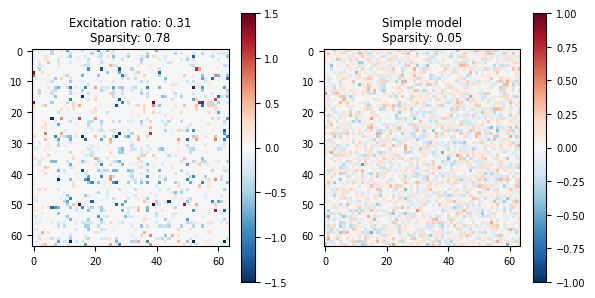

In [ ]:
weight = net.get_actual_weight().detach().cpu().numpy()
fig, ax = plt.subplots(1,2,figsize=(6,3))
limit = 1.5
im = ax[0].imshow(weight, cmap='RdBu_r', vmin=-limit, vmax=limit)
sparsity = 1 - np.mean(np.abs(weight)>0.1*np.std(np.abs(weight)))
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
# mask = F.gumbel_softmax(net.lstm.eimask_logit, tau=0.1, hard=False, dim=-1).detach().cpu().numpy()
exc_ratio = np.mean(eimask[:, 0] > eimask[:, 1])
ax[0].set_title(f'Excitation ratio: {exc_ratio:.2f}\nSparsity: {sparsity:.2f}')
plt.colorbar(im, ax=ax[0])

weight_simple = simple_net.get_actual_weight().detach().cpu().numpy()
im = ax[1].imshow(weight_simple, cmap='RdBu_r', vmin=-1, vmax=1)
sparsity_simple = 1 - np.mean(np.abs(weight_simple)>0.1*np.std(np.abs(weight_simple)))
ax[1].set_title(f'Simple model\nSparsity: {sparsity_simple:.2f}')
plt.colorbar(im, ax=ax[1])
plt.tight_layout()


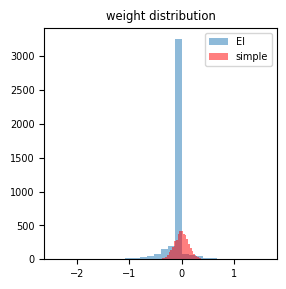

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(3,3))
ax.hist(weight.flatten(),bins=30, color='C0', label='EI', alpha=0.5)
ax.hist(weight_simple.flatten(),bins=30, color='red', label='simple', alpha=0.5)
ax.legend()
plt.title('weight distribution')
plt.show()

In [ ]:
torch.save(net.state_dict(), './model/sort/ei_net.pth')
torch.save(simple_net.state_dict(), './model/sort/simple_net.pth')
config = {'input_size': input_size, 'output_size':output_size,
          'hidden_size': hidden_size, 'epochs': epochs,
          'seq_len':5}
with open('./model/sort/model_config.json','w',encoding='utf-8') as f:
    import json
    json.dump(config, f, ensure_ascii=False)

In [ ]:
print(config)

{'input_size': 1, 'output_size': 2, 'hidden_size': 64, 'epochs': 2000, 'seq_len': 5}


## 8. Test Predictions Visualization


In [ ]:
from pdm_model import Net, SimpleNet
device='cuda:0'
batch_size = 64
hidden_size = 64
input_size = train_dataset.input_size  # [number, indicator]
output_size = train_dataset.output_size  # regression output
simple_net = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)
net = Net(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)
net_path = './model/sort/ei_net.pth'
simple_net_path = './model/sort/simple_net.pth'
net.load_state_dict(torch.load(net_path))
simple_net.load_state_dict(torch.load(simple_net_path))

<All keys matched successfully>

In [ ]:
n_test = 10
def plot_activity(hidden_size, net, idxs, color):
    fig, ax = plt.subplots((hidden_size-1)//8+1, 8, figsize=(32, (hidden_size//8+1)*3))
    ax = ax.flatten()
    input_seq, target = test_dataset[idxs]
    seq_len = input_seq.shape[1]


    batch_inputs = input_seq.transpose(0,1).to(device)
    outputs, eimask_logit, hidden = net(batch_inputs)
    h_all = hidden[0].detach().cpu().numpy()
    h_all_mean = h_all.mean(1)
    h_all_std = h_all.std(1)
    print('h_all_std:', h_all_std)
    for j in range(hidden_size):
        ax[j].plot(h_all_mean[:,j], color=color)
        ax[j].fill_between(np.arange(seq_len), h_all_mean[:,j]-h_all_std[:,j], h_all_mean[:,j]+h_all_std[:,j],
                           alpha=0.2, color=color)
    normalized_variance = (h_all_std/(h_all.max((0,1))-h_all.min((0,1)))).mean()

    plt.suptitle(f'Normalized variance: {normalized_variance:.4f}', fontsize=30)
    plt.tight_layout()
    plt.show()
    plt.close()

idxs = np.random.randint(0, len(test_dataset), n_test)

h_all_std: [[3.8876319e-01 1.3132517e-01 1.5320560e-01 ... 9.7749755e-02
  3.4304681e-01 2.8631085e-01]
 [1.8167752e-01 1.6452681e-03 1.0133410e-03 ... 1.3550066e-03
  6.1721803e-06 2.0731670e-01]
 [5.4680115e-01 5.1388398e-02 9.6862577e-02 ... 5.3944033e-02
  2.7210391e-01 6.7007780e-01]
 ...
 [1.3670090e-01 2.3836628e-02 4.4025872e-02 ... 9.9899303e-03
  2.0256141e-01 4.4733572e-01]
 [3.4985170e-01 2.3588270e-02 1.5729772e-01 ... 4.6183355e-02
  7.3184675e-01 3.1926817e-01]
 [2.0027804e-01 1.9445898e-02 6.3985601e-02 ... 1.0811408e-02
  2.1852875e-01 6.5040398e-01]]


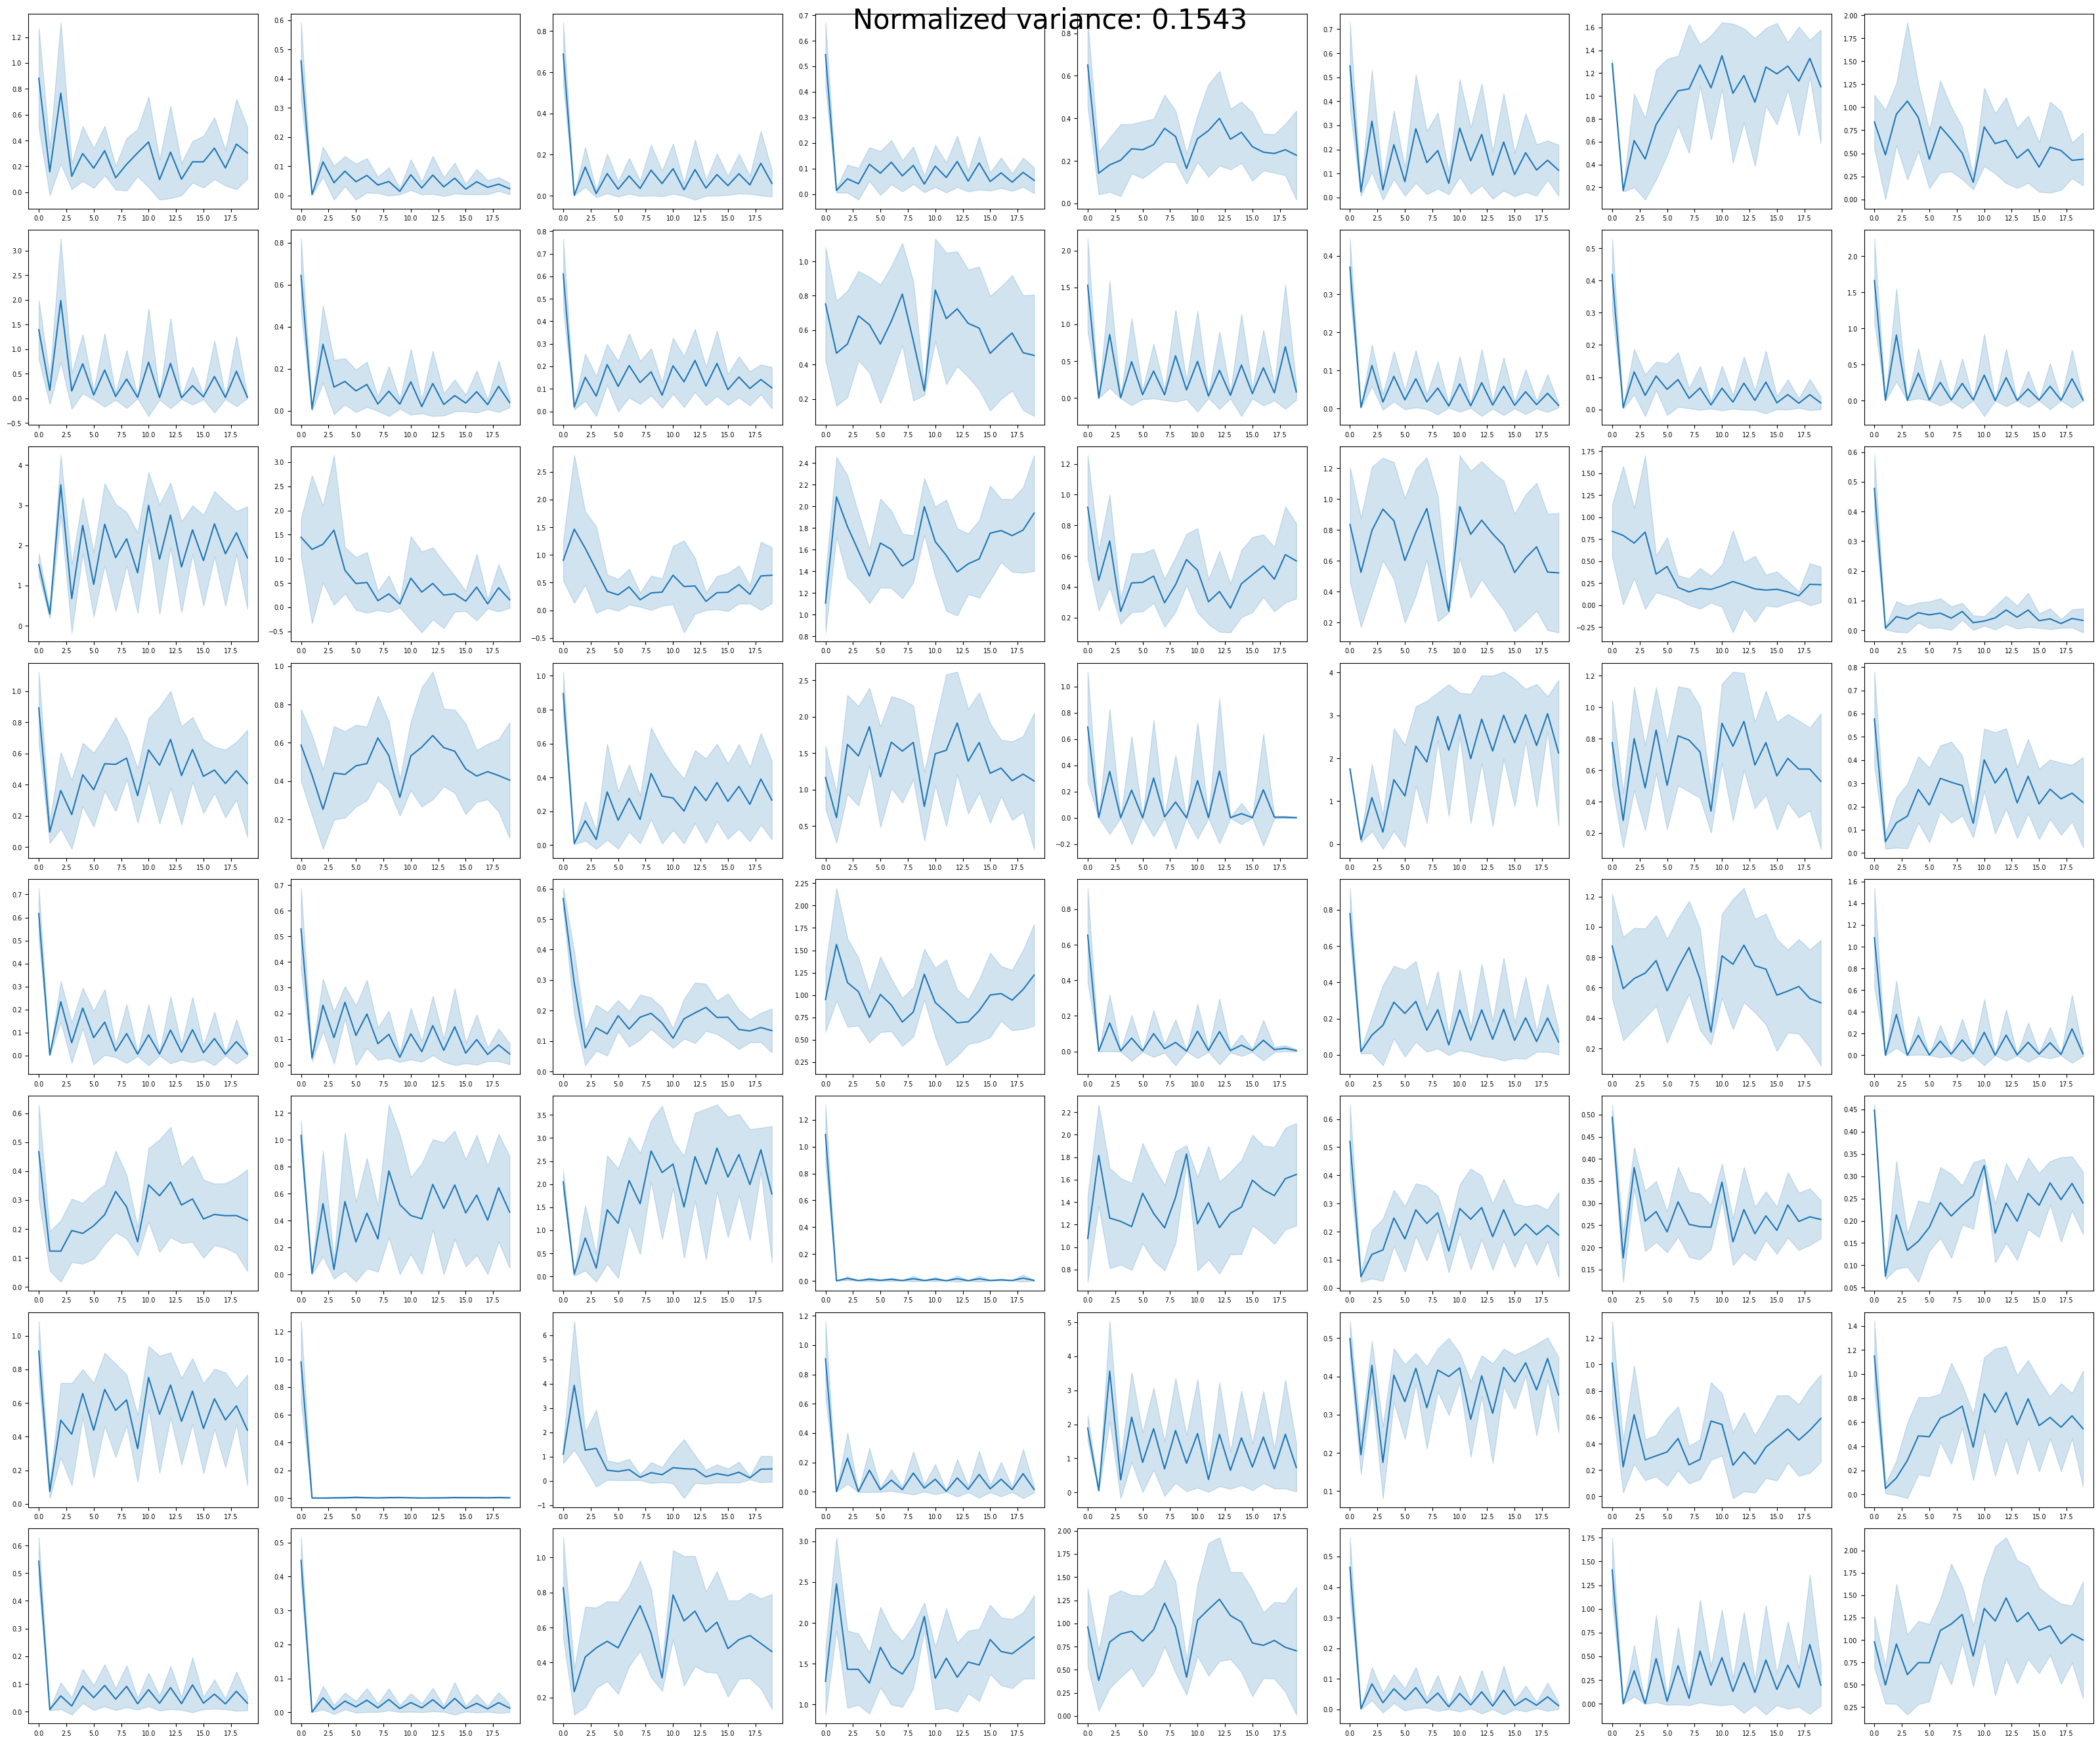

In [ ]:
plot_activity(hidden_size, net, idxs, 'C0')

h_all_std: [[0.0233712  0.10195336 0.16951168 ... 0.05275436 0.12710792 0.21894576]
 [0.12902366 0.22996467 0.18255995 ... 0.15498619 0.19606121 0.31068093]
 [0.12165131 0.35953042 0.2575781  ... 0.2665797  0.25109598 0.3725502 ]
 ...
 [0.41998002 0.35265666 0.2751548  ... 0.32862988 0.7729888  0.23535906]
 [0.098321   0.41370717 0.22070059 ... 0.41222927 0.8137305  0.12046649]
 [0.11462673 0.28428406 0.5988361  ... 0.76200515 0.03285928 0.58830875]]


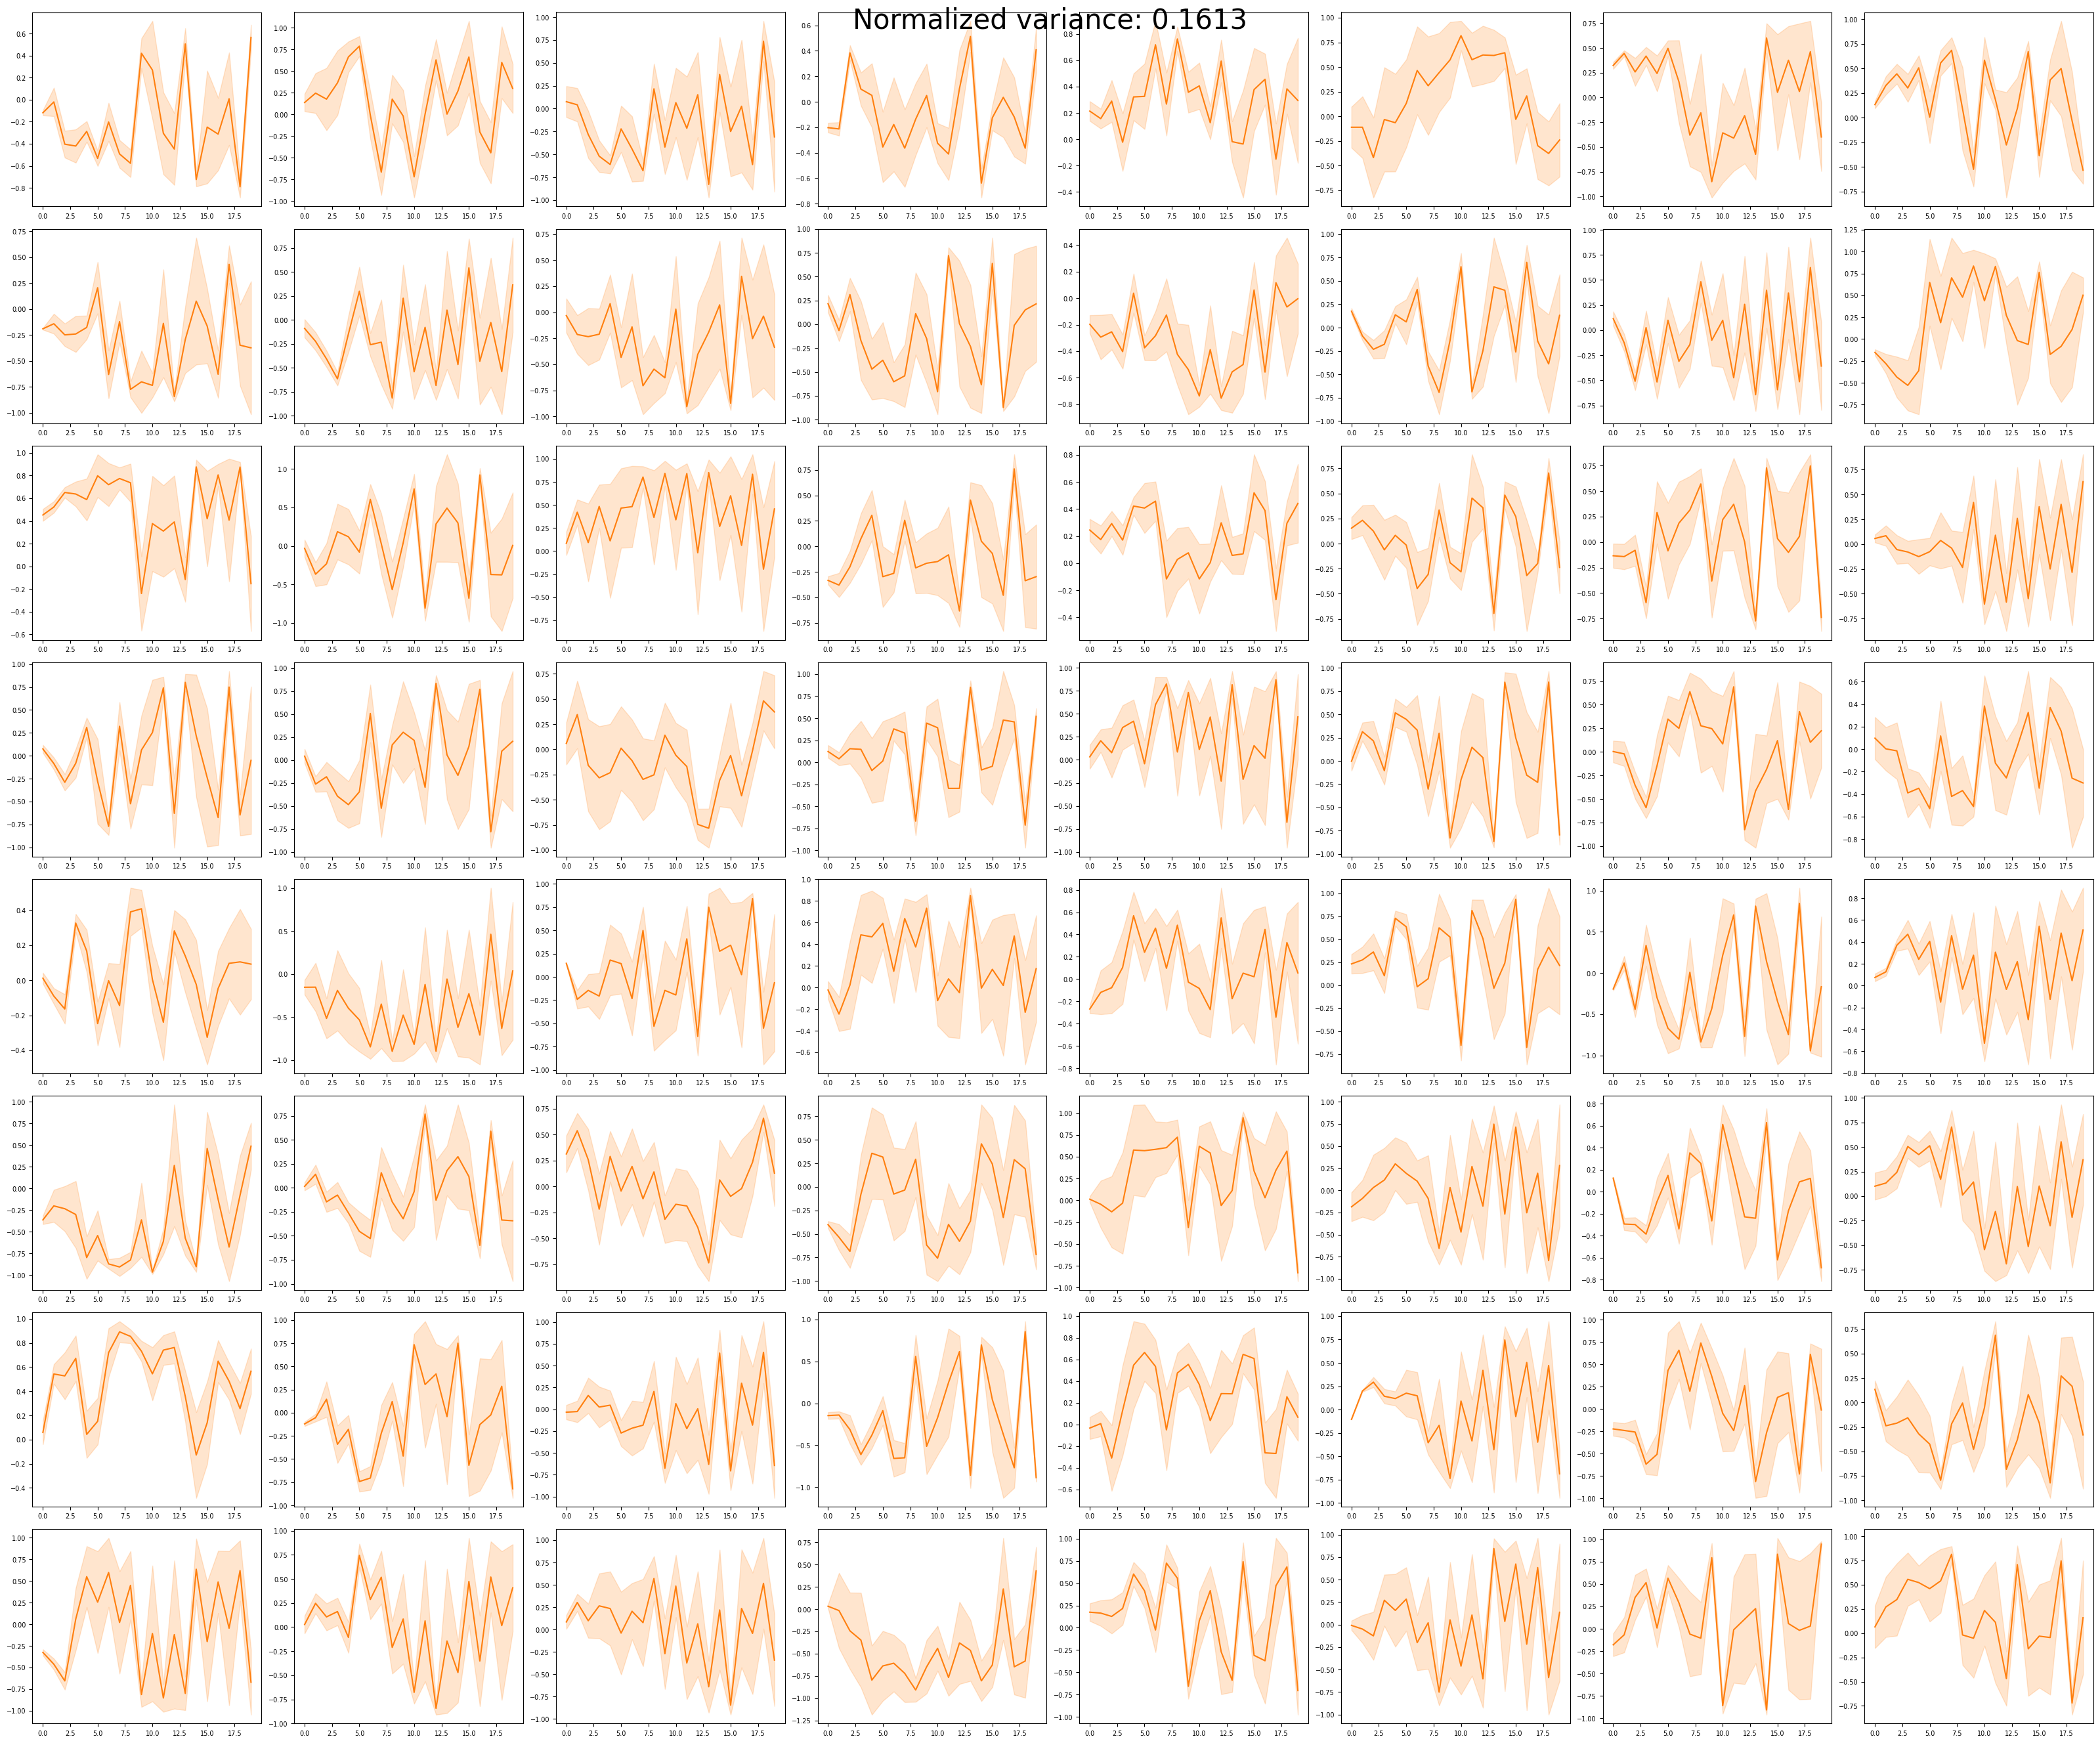

In [ ]:
plot_activity(hidden_size, simple_net, idxs, 'C1')